# **Day 45: Object Oriented Programming (Part 5) - Inheritance**

**Inheritance** means a new class **gets all the data and methods** of an existing class, and can also add new things or change old ones.

**Real-life example:** A child gets some features from the parents, but also has its own new features.

- The existing class is called the **parent class** (or base class).
- The new class is called the **child class** (or derived class).

Inheritance shows an **"is-a"** relationship:
- A **Bus** is a Vehicle.
- A **Tram** is a Vehicle.

In [1]:
class Vehicle:
    def __init__(self, number, capacity):
        self.number = number
        self.capacity = capacity
        self.passengers = 0

    def board(self, n):
        can_board = min(n, self.capacity - self.passengers)
        self.passengers += can_board
        return can_board

    def describe(self):
        return f"{type(self).__name__} {self.number}: {self.passengers}/{self.capacity} passengers"

# Bus gets everything from Vehicle
class Bus(Vehicle):
    pass

b = Bus("WB 19 1234", 50)
b.board(60)
print(b.describe())

Bus WB 19 1234: 50/50 passengers


The `Bus` class has no code of its own, but it can still use `board()` and `describe()`, because it **inherited** them from `Vehicle`.

## **Adding New Methods and Changing Old Ones (Method Overriding)**
- **super():** Used to call the parent class's method from the child class.
- **Method overriding:** When the child class writes its own version of a method that already exists in the parent.

In [2]:
class Tram(Vehicle):
    def __init__(self, number, capacity, route):
        super().__init__(number, capacity)     # Let the parent set the common data
        self.route = route                     # New data only for Tram

    def describe(self):                        # Overriding the parent's method
        return super().describe() + f" on route {self.route}"

    def ring_bell(self):                       # New method only for Tram
        return "Ting ting!"

t = Tram("T-5", 200, "Esplanade - Shyambazar")
t.board(120)
print(t.describe())
print(t.ring_bell())

Tram T-5: 120/200 passengers on route Esplanade - Shyambazar
Ting ting!


Let us understand the code above:
- `super().__init__(number, capacity)`: Calls the `__init__` of `Vehicle`, so we do not have to write the same code again.
- `describe()` in `Tram` **overrides** the parent's `describe()`, but it still uses the parent's text with `super().describe()` and adds the route.

## **Class Diagram of Inheritance**

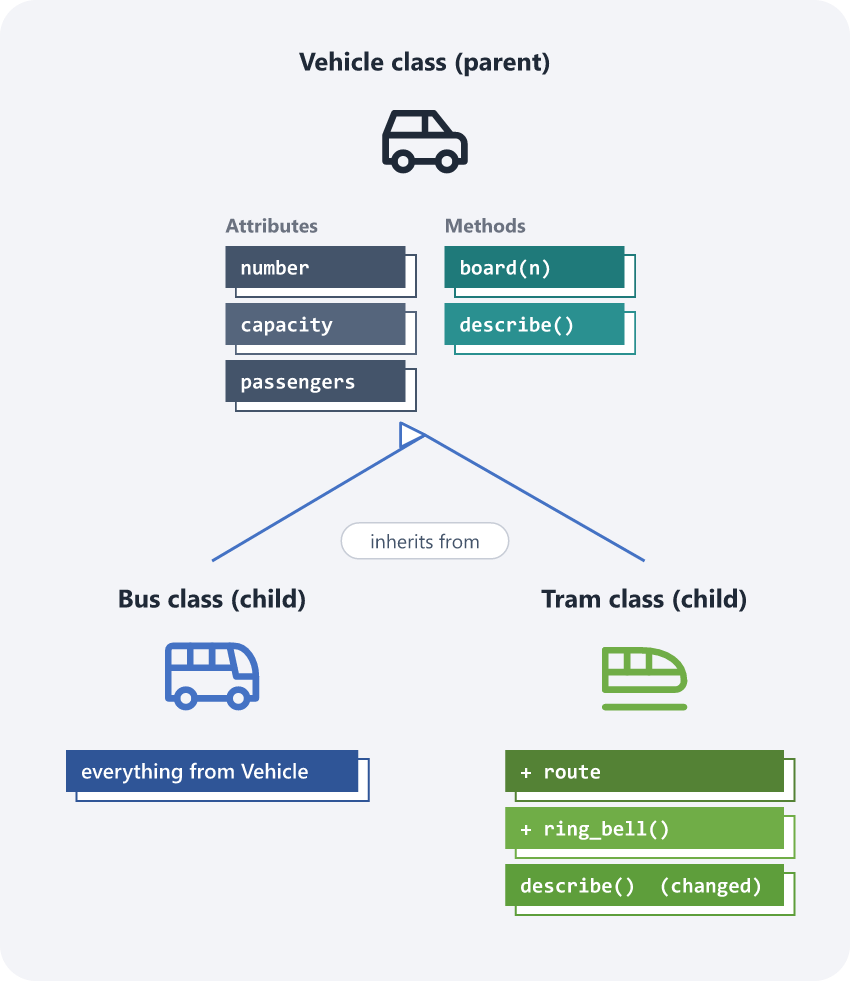

The arrow points **from the child to the parent**.

## **Example from GIS: Geometry Types**
In GIS, there are three basic shapes (called **geometries**): **Point**, **Line** and **Polygon**. All of them have some things in common (a name, a type, the ability to become GeoJSON), but each one calculates its size differently:
- A Point has no size.
- A Line has a **length**.
- A Polygon has an **area**.

This is a perfect case for inheritance. We use simple flat (x, y) coordinates in metres here to keep the maths easy.

In [3]:
import math

class Geometry:
    def __init__(self, name, coords):
        self.name = name
        self.coords = coords

    def geom_type(self):
        return type(self).__name__

    def size(self):
        return 0

    def to_geojson(self):
        return {"type": "Feature",
                "geometry": {"type": self.geojson_type, "coordinates": self.coords},
                "properties": {"name": self.name}}

class Point(Geometry):
    geojson_type = "Point"

class Line(Geometry):
    geojson_type = "LineString"

    def size(self):                 # Length of the line
        total = 0
        for (x1, y1), (x2, y2) in zip(self.coords, self.coords[1:]):
            total += math.hypot(x2 - x1, y2 - y1)
        return total

class Polygon(Geometry):
    geojson_type = "Polygon"

    def size(self):                 # Area using the Shoelace formula
        pts = self.coords
        s = 0
        for (x1, y1), (x2, y2) in zip(pts, pts[1:] + pts[:1]):
            s += x1 * y2 - x2 * y1
        return abs(s) / 2

    def to_geojson(self):
        g = super().to_geojson()
        ring = self.coords + [self.coords[0]]          # Repeat the first point to close the shape
        g["geometry"]["coordinates"] = [ring]           # A polygon needs one extra list
        return g

In [4]:
well = Point("Tube well", [120, 40])
road = Line("Village road", [[0, 0], [300, 0], [300, 400]])
field = Polygon("Paddy field", [[0, 0], [100, 0], [100, 50], [0, 50]])

for g in [well, road, field]:
    print(f"{g.geom_type():<8} {g.name:<14} size = {g.size():,.1f}")

print(field.to_geojson())

Point    Tube well      size = 0.0
Line     Village road   size = 700.0
Polygon  Paddy field    size = 5,000.0
{'type': 'Feature', 'geometry': {'type': 'Polygon', 'coordinates': [[[0, 0], [100, 0], [100, 50], [0, 50], [0, 0]]]}, 'properties': {'name': 'Paddy field'}}


- The `Line` length is 300 m + 400 m = **700 m**.
- The `Polygon` is a 100 m x 50 m field, so the area is **5,000 square metre** (0.5 hectare).
- The **Shoelace formula** is a well-known method to calculate the area of any polygon from its corner points. GIS software uses a similar method.
- `to_geojson()` is written **only once** in the parent class, but all three children can use it.
- `Polygon` **overrides** `to_geojson()`, because in GeoJSON a polygon's points are written inside one extra list, and the first point is repeated at the end to close the shape.

## **isinstance() and issubclass()**

In [5]:
print(isinstance(field, Polygon), isinstance(field, Geometry), isinstance(field, Line))
print(issubclass(Line, Geometry), issubclass(Geometry, object))

True True False
True True


Every class in Python inherits from a built-in class called `object`.

## **Multilevel Inheritance**
A child can also have its own child: Grandparent -> Parent -> Child.

In [6]:
class ElectricBus(Bus):
    def __init__(self, number, capacity, battery_kwh):
        super().__init__(number, capacity)
        self.battery_kwh = battery_kwh

    def describe(self):
        return super().describe() + f" [Electric, {self.battery_kwh} kWh]"

eb = ElectricBus("WB 25 EV 01", 40, 320)
eb.board(33)
print(eb.describe())

ElectricBus WB 25 EV 01: 33/40 passengers [Electric, 320 kWh]


## **When Not to Use Inheritance: Composition**
If the relationship is **"has-a"** instead of "is-a", we should not use inheritance. We should put one object **inside** another. This is called **composition**.

A **Train has coaches**. A Train is **not** a Coach.

In [7]:
class Coach:
    def __init__(self, code, seats):
        self.code = code
        self.seats = seats

class Train:
    def __init__(self, name, coaches):
        self.name = name
        self.coaches = coaches          # A list of Coach objects

    def total_seats(self):
        return sum(c.seats for c in self.coaches)

train = Train("Darjeeling Mail", [Coach("A1", 46), Coach("B1", 64)] + [Coach(f"S{i}", 72) for i in range(1, 9)])
print(train.name, "- total seats:", train.total_seats())

Darjeeling Mail - total seats: 686


In [8]:
# Quick question
# What will be printed?
# class A:
#     def hi(self):
#         return "A"
# class B(A):
#     def hi(self):
#         return "B" + super().hi()
# print(B().hi())